# RoadGuard AI
## Intelligent Road Infrastructure Monitoring System

**Project:** Road damage classification using deep learning  
**Dataset:** RDD2022 – India subset  
**Model:** MobileNetV2 transfer learning  
**Task:** Multi-label image classification

### Project objective
RoadGuard AI analyses road images and predicts whether four selected types of road damage are present.

| Class | Description |
|---|---|
| D00 | Longitudinal cracks |
| D10 | Transverse cracks |
| D20 | Alligator cracks |
| D40 | Potholes |

This is a research and demonstration prototype, not a replacement for professional road inspection.


## 1. Environment and imports

The notebook uses the project's existing Python environment and source modules.
Run it from the project root or from the `notebooks` directory.


In [1]:
from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Locate the project root
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "src").exists():
    raise FileNotFoundError(
        "Could not locate the src directory. "
        "Open this notebook from the RoadGuard AI project."
    )

os.chdir(PROJECT_ROOT)

from src.image_loader import create_dataset, IMAGE_SIZE, CLASSES
from src.prediction import predict_road_damage

print("Project root:", PROJECT_ROOT)
print("TensorFlow version:", tf.__version__)
print("Image size:", IMAGE_SIZE)
print("Classes:", CLASSES)


I0000 00:00:1795460168.151512   42258 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795460168.152252   42258 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795460169.189678   42258 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795460172.132028   42258 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

Project root: /home/lenovo/projects/roadguard-ai
TensorFlow version: 2.21.0
Image size: (160, 160)
Classes: ['D00', 'D10', 'D20', 'D40']


## 2. Dataset overview

The project uses the India subset of RDD2022. Its original annotations contain road-damage bounding boxes in XML format.

For this project, the annotations were converted into four binary target columns. Each target indicates whether the corresponding damage class appears in an image.

**Important:** A zero in these four columns means that the selected class was not annotated. It does not necessarily mean that the road is completely undamaged.


In [2]:
DATA_DIR = PROJECT_ROOT / "data" / "processed"

train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "validation.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Total images:", len(train_df) + len(val_df) + len(test_df))

display(train_df.head())


Training images: 5394
Validation images: 1156
Test images: 1156
Total images: 7706


,image_filename,image_path,xml_path,labels,object_count,unique_class_count,has_image,D00,D10,D20,D40
0,India_000000.jpg,data/raw/RDD2022_India/India/train/images/Indi...,data/raw/RDD2022_India/India/train/annotations...,NaN,0,0,True,0,0,0,0
1,India_000001.jpg,data/raw/RDD2022_India/India/train/images/Indi...,data/raw/RDD2022_India/India/train/annotations...,NaN,0,0,True,0,0,0,0
2,India_000002.jpg,data/raw/RDD2022_India/India/train/images/Indi...,data/raw/RDD2022_India/India/train/annotations...,NaN,0,0,True,0,0,0,0
3,India_000010.jpg,data/raw/RDD2022_India/India/train/images/Indi...,data/raw/RDD2022_India/India/train/annotations...,D44,1,1,True,0,0,0,0
4,India_000011.jpg,data/raw/RDD2022_India/India/train/images/Indi...,data/raw/RDD2022_India/India/train/annotations...,D00,1,1,True,1,0,0,0


## 3. Dataset split and class distribution

The data was divided into training, validation, and test sets using a multi-label stratified split.

- Training: 70%
- Validation: 15%
- Test: 15%

The split was designed to preserve the distribution of the selected damage labels across the three subsets.


,Training,Validation,Test
D00,776,167,166
D10,42,9,9
D20,1231,263,264
D40,1071,229,230


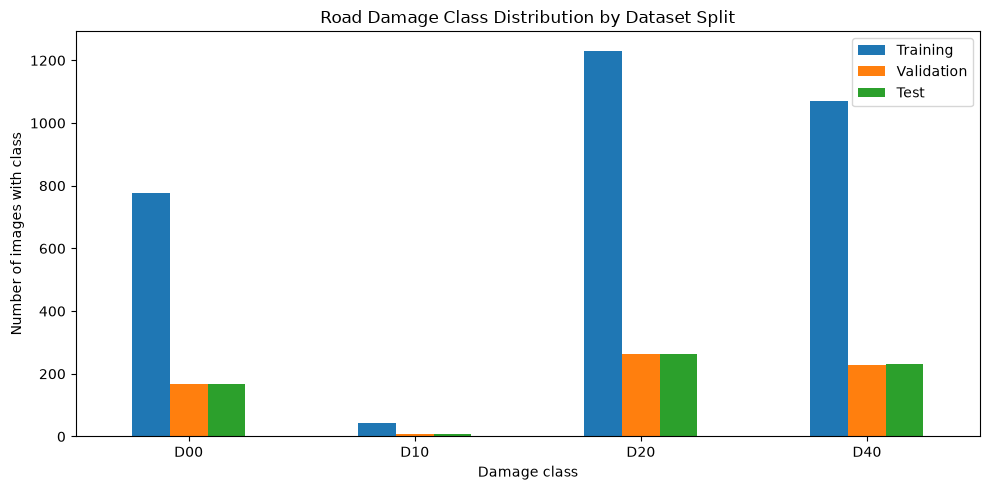

In [3]:
split_data = {
    "Training": train_df,
    "Validation": val_df,
    "Test": test_df
}

distribution = pd.DataFrame({
    split_name: df[CLASSES].sum()
    for split_name, df in split_data.items()
})

display(distribution)

distribution.plot(kind="bar", figsize=(10, 5))
plt.title("Road Damage Class Distribution by Dataset Split")
plt.xlabel("Damage class")
plt.ylabel("Number of images with class")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 4. Inspect sample images

The following cell displays real images from the training dataset and their selected labels.


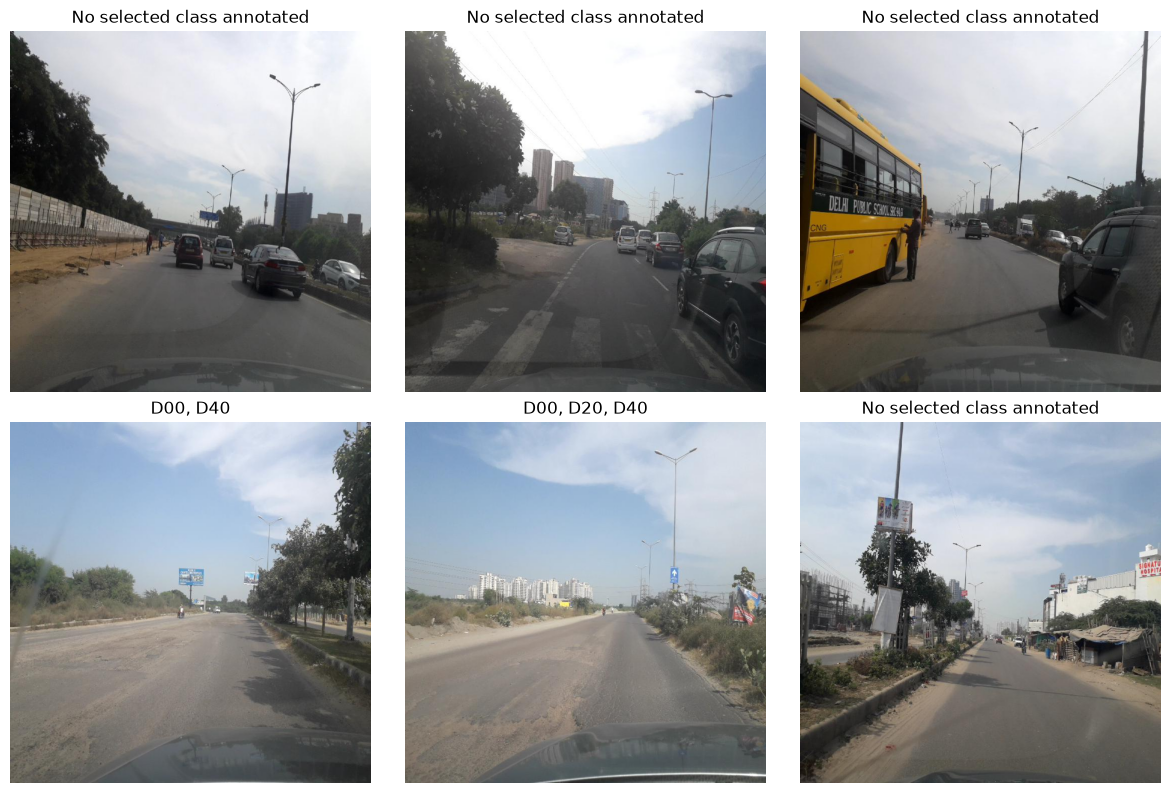

In [4]:
from PIL import Image

sample_count = min(6, len(train_df))
sample_rows = train_df.sample(sample_count, random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample_rows.iterrows()):
    image_path = Path(row["image_path"])
    image = Image.open(image_path).convert("RGB")

    labels = [name for name in CLASSES if int(row[name]) == 1]
    label_text = ", ".join(labels) if labels else "No selected class annotated"

    ax.imshow(image)
    ax.set_title(label_text)
    ax.axis("off")

for ax in axes[sample_count:]:
    ax.axis("off")

plt.tight_layout()
plt.show()


## 5. Image preprocessing

The project's image loader performs the following operations:

1. Reads each image from its file path.
2. Decodes the JPEG image into three colour channels.
3. Resizes it to 160 × 160 pixels.
4. Converts pixel values to floating-point values.
5. Groups images into batches of eight.
6. Shuffles the training dataset and prefetches batches.

The model itself applies MobileNetV2's expected input scaling from the 0–255 pixel range to the -1–1 range.


In [5]:
train_dataset = create_dataset(
    DATA_DIR / "train.csv",
    training=True
)

validation_dataset = create_dataset(
    DATA_DIR / "validation.csv",
    training=False
)

test_dataset = create_dataset(
    DATA_DIR / "test.csv",
    training=False
)

images, labels = next(iter(train_dataset))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Image pixel range:", float(tf.reduce_min(images)),
      "to", float(tf.reduce_max(images)))
print("Target classes:", CLASSES)


E0000 00:00:1795460175.817634   42258 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Image batch shape: (8, 160, 160, 3)
Label batch shape: (8, 4)
Image data type: <dtype: 'float32'>
Image pixel range: 0.0 to 255.0
Target classes: ['D00', 'D10', 'D20', 'D40']


## 6. Model architecture

RoadGuard AI uses MobileNetV2 with ImageNet-pretrained weights as its feature extraction backbone.

The original backbone is frozen during the project's initial training stage. A classification head is added:

- Global Average Pooling
- Dropout with a rate of 0.3
- Dense output layer with four sigmoid units

Sigmoid outputs allow each damage class to be predicted independently. This is appropriate because one road image may contain more than one damage type.

The model uses the Adam optimizer and binary cross-entropy loss.


In [6]:
MODEL_PATH = PROJECT_ROOT / "models" / "roadguard_best.keras"

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Trained model not found: {MODEL_PATH}")

model = tf.keras.models.load_model(MODEL_PATH)

print("Loaded model:", MODEL_PATH)
model.summary()


Loaded model: /home/lenovo/projects/roadguard-ai/models/roadguard_best.keras


Model: "RoadGuard_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ damage_predictions (Dense)      │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,273,358 (8.67 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 10,250 (40.04 KB)

## 7. Training methodology and optimization

The training implementation is available in `src/train.py` and `src/model.py`.

The project uses:
- Transfer learning with MobileNetV2.
- A frozen pretrained feature extractor.
- Dropout regularization.
- Adam optimizer with a learning rate of 0.0001.
- Binary cross-entropy loss.
- Early stopping based on validation loss.
- Learning-rate reduction when validation performance stops improving.
- Model checkpointing to preserve the best validation model.

**Training history note:** The original training-history CSV is not currently available in the project outputs. Therefore, this notebook does not fabricate or display training curves.

### Optional retraining

The following cell is disabled by default. Change `RUN_TRAINING` to `True` only when you intentionally want to run a new training experiment. It saves to a separate model filename rather than overwriting the existing model.


In [7]:
RUN_TRAINING = False

if RUN_TRAINING:
    from src.model import build_model

    from tensorflow.keras.callbacks import (
        EarlyStopping,
        ReduceLROnPlateau,
        ModelCheckpoint
    )

    training_model = build_model()

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-7
        ),
        ModelCheckpoint(
            "models/roadguard_notebook_best.keras",
            monitor="val_loss",
            save_best_only=True
        )
    ]

    history = training_model.fit(
        create_dataset(DATA_DIR / "train.csv", training=True),
        validation_data=create_dataset(DATA_DIR / "validation.csv"),
        epochs=20,
        callbacks=callbacks
    )

    training_model.save("models/roadguard_notebook_final.keras")
    pd.DataFrame(history.history).to_csv(
        "outputs/notebook_training_history.csv",
        index=False
    )

    print("Optional training experiment completed.")
else:
    print("Optional training skipped. Existing trained model will be evaluated.")


Optional training skipped. Existing trained model will be evaluated.


## 8. Load decision thresholds

The model produces a probability for each class. A class is marked as detected when its probability meets or exceeds its configured threshold.

The thresholds were tuned using the validation data and saved in `models/thresholds.json`.


In [8]:
THRESHOLD_PATH = PROJECT_ROOT / "models" / "thresholds.json"

with open(THRESHOLD_PATH, "r") as file:
    thresholds = json.load(file)

threshold_array = np.array([thresholds[name] for name in CLASSES])

threshold_table = pd.DataFrame({
    "Class": CLASSES,
    "Threshold": threshold_array
})

display(threshold_table)


,Class,Threshold
0,D00,0.232173
1,D10,0.070398
2,D20,0.238324
3,D40,0.259906


## 9. Evaluate the model on the test dataset

The following evaluation calculates:
- Macro precision
- Macro recall
- Macro F1-score
- Micro F1-score
- Macro ROC-AUC

It also produces a class-by-class classification report.

The configured thresholds are applied to the predicted probabilities to produce binary predictions.


In [9]:
y_true_batches = []
for _, batch_labels in test_dataset:
    y_true_batches.append(batch_labels.numpy())

y_true = np.concatenate(y_true_batches, axis=0)

y_prob = model.predict(test_dataset, verbose=1)
y_pred = (y_prob >= threshold_array).astype(int)

print("True label shape:", y_true.shape)
print("Predicted probability shape:", y_prob.shape)
print("Predicted label shape:", y_pred.shape)

macro_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
macro_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)
micro_f1 = f1_score(
    y_true, y_pred, average="micro", zero_division=0
)

# ROC-AUC requires both positive and negative examples for each class.
class_auc = []
for index, class_name in enumerate(CLASSES):
    if len(np.unique(y_true[:, index])) == 2:
        class_auc.append(
            roc_auc_score(y_true[:, index], y_prob[:, index])
        )
    else:
        print("ROC-AUC unavailable for:", class_name)

macro_roc_auc = float(np.mean(class_auc)) if class_auc else float("nan")

metrics = pd.DataFrame({
    "Metric": [
        "Macro Precision",
        "Macro Recall",
        "Macro F1-score",
        "Micro F1-score",
        "Macro ROC-AUC"
    ],
    "Score": [
        macro_precision,
        macro_recall,
        macro_f1,
        micro_f1,
        macro_roc_auc
    ]
})

display(metrics)


145/145 ━━━━━━━━━━━━━━━━━━━━ 18s 120ms/step
True label shape: (1156, 4)
Predicted probability shape: (1156, 4)
Predicted label shape: (1156, 4)


,Metric,Score
0,Macro Precision,0.337747
1,Macro Recall,0.467128
2,Macro F1-score,0.381597
3,Micro F1-score,0.486800
4,Macro ROC-AUC,0.755175


In [10]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASSES,
        zero_division=0
    )
)


              precision    recall  f1-score   support

         D00       0.33      0.42      0.37       166
         D10       0.05      0.22      0.08         9
         D20       0.48      0.72      0.57       264
         D40       0.49      0.51      0.50       230

   micro avg       0.43      0.57      0.49       669
   macro avg       0.34      0.47      0.38       669
weighted avg       0.44      0.57      0.49       669
 samples avg       0.21      0.22      0.20       669



## 10. Per-class evaluation

The next chart compares precision, recall, and F1-score for each damage category.


,Class,Precision,Recall,F1-score
0,D00,0.331754,0.421687,0.371353
1,D10,0.050000,0.222222,0.081633
2,D20,0.479695,0.715909,0.574468
3,D40,0.489540,0.508696,0.498934


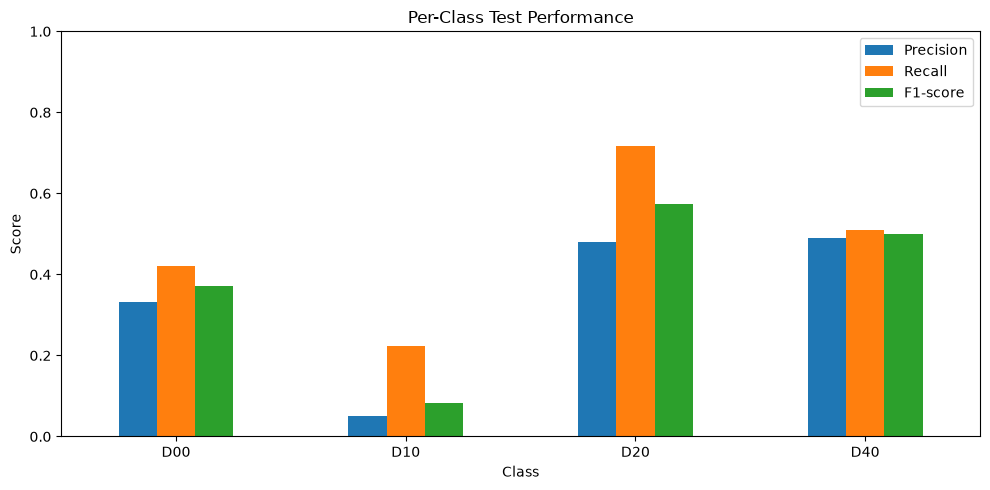

In [11]:
per_class_precision = precision_score(
    y_true, y_pred, average=None, zero_division=0
)
per_class_recall = recall_score(
    y_true, y_pred, average=None, zero_division=0
)
per_class_f1 = f1_score(
    y_true, y_pred, average=None, zero_division=0
)

per_class_results = pd.DataFrame({
    "Class": CLASSES,
    "Precision": per_class_precision,
    "Recall": per_class_recall,
    "F1-score": per_class_f1
})

display(per_class_results)

per_class_results.set_index("Class").plot(
    kind="bar",
    figsize=(10, 5)
)
plt.title("Per-Class Test Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 11. Single-image prediction

This section uses the project's prediction function to classify one image from the test split.

The output includes the probability, decision threshold, and detection result for each selected class.

A negative result means that the model did not cross the configured threshold. It does not prove that the road has no damage.


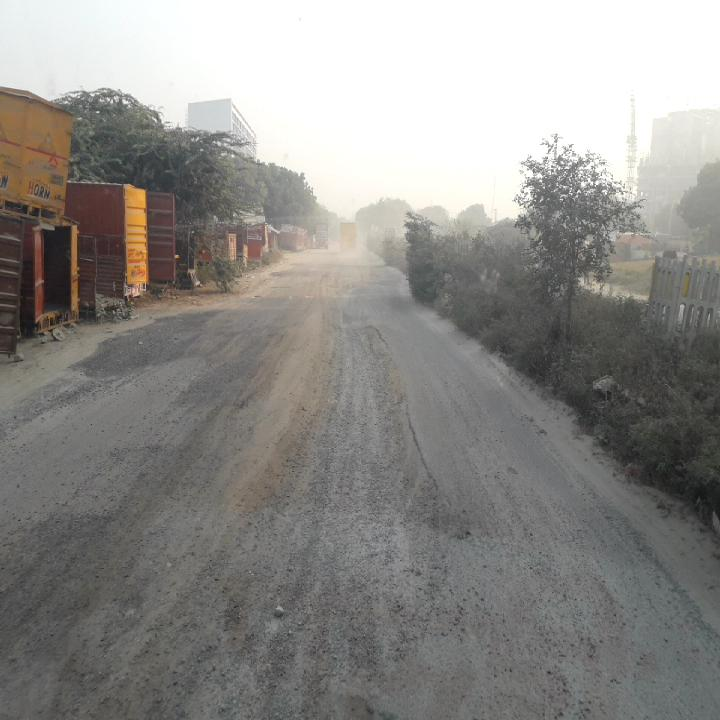

,Class,Probability,Threshold,Detected
0,D00,0.3102,0.2322,True
1,D10,0.0912,0.0704,True
2,D20,0.1314,0.2383,False
3,D40,0.4214,0.2599,True


Image: India_000003.jpg


In [12]:
example_image = str(test_df.iloc[0]["image_path"])

prediction = predict_road_damage(example_image)

display(Image.open(example_image).convert("RGB"))

prediction_rows = []
for class_name, result in prediction["predictions"].items():
    prediction_rows.append({
        "Class": class_name,
        "Probability": result["probability"],
        "Threshold": result["threshold"],
        "Detected": result["detected"]
    })

prediction_table = pd.DataFrame(prediction_rows)
display(prediction_table)

print("Image:", prediction["image"])


## 12. Limitations and considerations

1. **Class imbalance:** Some damage types, especially D10, have far fewer positive examples than other classes. Their evaluation results are less reliable.
2. **Limited class scope:** The model predicts only D00, D10, D20, and D40. It does not identify every road-damage category in RDD2022.
3. **Annotation interpretation:** An image without one of the selected annotations should not automatically be treated as a completely undamaged road.
4. **Geographic scope:** This experiment uses the India subset of RDD2022. Performance in other countries and road environments has not been established.
5. **Image classification:** The model predicts whether damage classes appear in an image. It does not locate damage with bounding boxes or measure its physical size.
6. **Dataset sequence limitations:** Source sequence metadata was not available for a complete sequence-aware split. The random split may not fully account for correlations between nearby images.
7. **Test-set reuse:** The test set was used during earlier model evaluation and threshold experiments. Its results should therefore be treated as an operational estimate, not a completely untouched final benchmark.
8. **Prototype status:** RoadGuard AI is an academic prototype and should not independently determine road safety or maintenance decisions.


## 13. Conclusion

RoadGuard AI demonstrates an image-based deep learning workflow for identifying four selected road-damage categories.

The project includes:
- RDD2022 data inspection and annotation processing.
- Multi-label dataset preparation.
- Image preprocessing.
- MobileNetV2 transfer learning.
- Threshold-based multi-label prediction.
- Evaluation using multiple classification metrics.
- A prediction function that can be integrated into the project's API and dashboard.

Further work should focus on collecting more representative labelled images, improving performance on rare classes, and validating the system on independent road datasets.
